# 05 — Case study: precipitation type maps for 3 February 2022, 1800 UTC

This notebook rebuilds the case-study figure for the revised manuscript (ERA5-initialized AI-NWP runs). It replaces the old figure, which showed one ptype field per model.

**Systems (12)** — the same as notebooks 01–04:
- Aurora, GraphCast, WXFormer, FuXi and Pangu-Weather, each with **EDNN** and **Bourgouin** ptype.
- GFS with **EDNN** and its **native** ptype.

**Processing**
1. Forecast valid at **1800 UTC 3 February 2022**, forecast **day 1** (00Z init, 18-h lead, following the day/lead convention of notebook 01).
2. Every field is regridded (nearest neighbour, since ptype is categorical) onto a common 0.25° CONUS grid.
3. **CONUS mask:** grid points outside the CONUS land polygon (ocean, Great Lakes, Canada, Mexico) are removed.
4. **GFS no-ptype mask:** grid points where native GFS diagnoses no ptype (−1, i.e. no precipitation) are removed from **all 12 panels**. This is a display mask only. As in the rest of the manuscript, it is *not* used for any verification score.
5. mPING reports valid at the same time, with the observed class assigned by the same rule as notebooks 01–04 (`OBS_RULE`).

**Analysis**
- **Figure 1:** mPING reports plus 12 ptype maps (EDNN and Bourgouin/native side by side for each model).
- **Figure 2:** agreement maps: (a) among the 6 EDNN systems, (b) among all 12 systems, (c) number of AI models for which EDNN and Bourgouin disagree. Observed ice pellet and freezing rain reports are overlaid.
- **Point verification:** each system scored against the case-time mPING reports at the nearest *native* grid point (no masks, as in notebook 01), including where observed ice pellets and freezing rain went.
- Optional: RAP 2-m temperature 0 °C / 4 °C contours on the maps (`OVERLAY_RAP_T2M`), linking the case to the near-freezing analysis in notebook 04.

**Outputs** (in `OUT` and `FIG`)

| File | Contents |
|---|---|
| `case_study_ptype_maps_<time>_day<d>.pdf` | Figure 1 |
| `case_study_agreement_<time>_day<d>.pdf` | Figure 2 |
| `case_study_point_verification_<time>_day<d>.csv` | Accuracy and per-class hits per system |
| `case_study_ip_fzra_fate_<time>_day<d>.csv` | Forecast class of observed IP / FZRA reports per system |

> Run with **Kernel → Restart & Run All**. Before the first run, check the **file lookup and variable names in Section 2** against notebook 01.

## 1. Imports

In [1]:
from pathlib import Path
import glob, re, warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree
import shapely
from shapely.geometry import box
from shapely.ops import unary_union
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

pd.set_option("display.max_columns", 100)

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 2. Configuration

**Check before the first run**
- `forecast_file()`: must find the same NetCDF files as `resolve_file` in notebook 01. The default assumes one file per model, init and lead under `MODEL_DIRS[model]`; **replace the body with notebook 01's `resolve_file` if the layout differs.**
- `PTYPE_VAR`: the ptype variable for each method. `None` means auto-detect from `VAR_PATTERNS`; Section 5 prints what was picked and every variable in each file.

**Case**
- `VALID`, `FORECAST_DAY`: valid time and forecast day. The init time and lead are derived with the notebook-01 rule (00Z init; day *n* covers leads 24(n−1)+6 … 24n h).

**Masks**
- `CONUS_SHAPEFILE`: path to a US (nation or states) shapefile. `None` uses Natural Earth states via cartopy (Great Lakes excluded). The union is clipped to `CONUS_BOX`, which removes Alaska, Hawaii and the territories.
- The GFS no-ptype mask is always applied to the maps and never to the scores.

In [2]:
# ============================================================
# OBSERVED-CLASS RULE AND mPING (must match notebooks 01–04)
# ============================================================
OBS_RULE = "modal"                    # "modal" | "consensus"
CONSENSUS = 70.0                      # used only when OBS_RULE == "consensus"
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
PTYPE_COLS = {"sn_percent": "Snow", "ra_percent": "Rain",
              "pl_percent": "Ice Pellet", "fzra_percent": "Freezing Rain"}

# ============================================================
# CASE
# ============================================================
VALID = pd.Timestamp("2022-02-03 18:00")
# FORECAST_DAY = 1

FORECAST_DAY = 1

def init_and_lead(valid, day):
    # Notebook-01 rule: 00Z init; a 00Z valid time belongs to the previous day's init.
    init = (valid - pd.Timedelta(hours=1)).floor("D") - pd.Timedelta(days=day - 1)
    lead = int((valid - init) / pd.Timedelta(hours=1))
    assert 24 * (day - 1) + 6 <= lead <= 24 * day, (init, lead)
    return init, lead

INIT, LEAD = init_and_lead(VALID, FORECAST_DAY)
TAG = f"{VALID:%Y%m%d_%H}z_day{FORECAST_DAY}"
print(f"Valid {VALID:%Y-%m-%d %H}Z, day {FORECAST_DAY} -> init {INIT:%Y-%m-%d %H}Z, lead {LEAD} h")

# ============================================================
# FORECAST FILES AND VARIABLES  (check against notebook 01)
# ============================================================
MODELS = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", "GFS"]

MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "WXFormer": AI_BASE / "wx_ptype",
    "FuXi": AI_BASE / "fuxi_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}
FILE_GLOBS = [                          # tried in order; the first unique match wins
    "{init:%Y-%m-%dT%H}Z/*_{lead:03d}.nc",      # e.g. 2022-02-03T00Z/aurora_2022-02-03T00Z_018.nc
    "{init:%Y-%m-%dT%H}Z/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead:03d}.nc",
    "*{init:%Y%m%d%H}*_{lead}.nc",
    "*{init:%Y%m%d%H}*_{lead:03d}.nc",
]

def forecast_file(model, init, lead):
    # Replace this body with notebook 01's resolve_file if the layout differs.
    tried = []
    for pat in FILE_GLOBS:
        p = str(MODEL_DIRS[model] / pat.format(init=init, lead=lead))
        hits = sorted(glob.glob(p))
        tried.append(p)
        if len(hits) == 1:
            return Path(hits[0])
        if len(hits) > 1:
            raise RuntimeError(f"{model}: {len(hits)} files match {p}")
    raise FileNotFoundError(f"{model}: no file for init {init}, lead {lead}. Tried:\n  " + "\n  ".join(tried))

PTYPE_VAR = {"EDNN": "ML_ptype", "Bourgouin": "BOURG_ptype", "Native": None}    # None = auto-detect
VAR_PATTERNS = {
    "EDNN": [r"^ML_ptype$"],
    "Bourgouin": [r"bourg"],
    "Native": [r"^ptype_gfs$", r"gfs.*ptype|ptype.*gfs", r"native", r"^ptype$"],
}

# ============================================================
# SYSTEMS, CLASSES, COLOURS  (same palette as notebooks 01–04)
# ============================================================
SYSTEM_ORDER = [
    "Aurora — EDNN", "Aurora — Bourgouin",
    "GraphCast — EDNN", "GraphCast — Bourgouin",
    "WXFormer — EDNN", "WXFormer — Bourgouin",
    "FuXi — EDNN", "FuXi — Bourgouin",
    "Pangu-Weather — EDNN", "Pangu-Weather — Bourgouin",
    "GFS — EDNN", "GFS — Native",
]
AI_MODELS = [m for m in MODELS if m != "GFS"]
CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
CLASS_COLORS = {"Rain": "#009E73", "Snow": "#56B4E9",
                "Ice Pellet": "#CC79A7", "Freezing Rain": "#D55E00"}
NONE_LABEL = "No ptype"
CMAP = ListedColormap([CLASS_COLORS[c] for c in CLASS_ORDER])
NORM = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], CMAP.N)

# ============================================================
# GRID, MASKS, MAP
# ============================================================
GRID_RES = 0.25
LAT_T = np.arange(20.0, 55.0 + 1e-9, GRID_RES)
LON_T = np.arange(-130.0, -60.0 + 1e-9, GRID_RES)
MAX_REGRID_KM = 60.0                   # target points farther than this from any source point -> NaN
MAX_POINT_KM = 30.0                    # mPING-to-grid distance limit (as notebook 01)

CONUS_SHAPEFILE = None                 # e.g. "/glade/u/home/<user>/shapefiles/cb_2018_us_nation_5m.shp"
CONUS_BOX = box(-128.0, 22.0, -64.0, 51.0)

MAP_EXTENT = [-120.0, -73.0, 23.0, 50.0]
PROJ = ccrs.LambertConformal(central_longitude=-96, central_latitude=39,
                             standard_parallels=(33, 45))
DRAW_STATES = True                     # needs Natural Earth data (cartopy download or local copy)

OVERLAY_RAP_T2M = False               # RAP 2-m T 0/4 °C contours (needs Herbie + internet)
RAP_SAVE_DIR = Path("/glade/derecho/scratch/sakor/herbie")

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7.5,
    "axes.titlesize": 8, "axes.labelsize": 7.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
LETTERS = "abcdefghijklmnopqrstuvwxyz"

Valid 2022-02-03 18Z, day 1 -> init 2022-02-03 00Z, lead 18 h


## 3. mPING reports at the case time

The same filtering and observed-class rule as notebooks 01–04, restricted to `VALID`. Reports outside the CONUS polygon (built in Section 4) are dropped in that section.

In [3]:
def assign_obs_class(d):
    # Identical to notebooks 01–04: most-reported ptype, ties FZRA > IP > Snow > Rain.
    raw = d[TIE_PRIORITY].astype(float).fillna(0.0)
    if raw.to_numpy().max() <= 1.0:
        raw = raw * 100.0
    pct = raw.round(6)
    d = d.copy()
    d["obs_consensus"] = raw.max(axis=1)
    d["obs_class"] = pct.idxmax(axis=1).map(PTYPE_COLS)
    if OBS_RULE == "consensus":
        keep = d.obs_consensus >= CONSENSUS
    elif OBS_RULE == "modal":
        keep = d.obs_consensus > 0
    else:
        raise ValueError(f"unknown OBS_RULE {OBS_RULE!r}")
    return d[keep]

cols = ["datetime", "lat", "lon"] + list(PTYPE_COLS)
obs = pd.read_parquet(MPING_PATH, columns=cols)
obs["datetime"] = pd.to_datetime(obs["datetime"])
obs = obs[obs.datetime == VALID]
obs = obs[obs.lat.between(LAT_MIN, LAT_MAX) & obs.lon.between(LON_MIN, LON_MAX)]
obs = assign_obs_class(obs).reset_index(drop=True)
obs["obs_code"] = obs.obs_class.map({v: k for k, v in CLASS_NAMES.items()})

print(f"mPING reports at {VALID:%Y-%m-%d %H}Z: {len(obs):,}")
display(obs.obs_class.value_counts().reindex(CLASS_ORDER, fill_value=0).to_frame("reports"))

mPING reports at 2022-02-03 18Z: 586


,reports
obs_class,
Rain,146
Snow,218
Ice Pellet,186
Freezing Rain,36


## 4. CONUS mask

The US polygon is clipped to `CONUS_BOX` (removing Alaska, Hawaii and the territories) and rasterized on the common grid. With Natural Earth, the "lakes" version of the state polygons is used, so the Great Lakes are excluded as well.

In [4]:
def load_conus_polygon():
    if CONUS_SHAPEFILE:
        geoms = list(shpreader.Reader(CONUS_SHAPEFILE).geometries())
        src = CONUS_SHAPEFILE
    else:
        path = shpreader.natural_earth(resolution="50m", category="cultural",
                                       name="admin_1_states_provinces_lakes")
        geoms = [r.geometry for r in shpreader.Reader(path).records()
                 if r.attributes.get("admin") == "United States of America"]
        src = "Natural Earth admin_1_states_provinces_lakes (50m)"
    poly = unary_union(geoms).intersection(CONUS_BOX)
    shapely.prepare(poly)
    print(f"CONUS polygon from {src}: {len(geoms)} shapes, bounds {np.round(poly.bounds, 1)}")
    return poly

CONUS = load_conus_polygon()
LON2D, LAT2D = np.meshgrid(LON_T, LAT_T)
CONUS_MASK = shapely.contains_xy(CONUS, LON2D, LAT2D)
print(f"Common grid {LAT_T.size} x {LON_T.size}; CONUS points: {CONUS_MASK.sum():,}")

in_conus = shapely.contains_xy(CONUS, obs.lon.to_numpy(), obs.lat.to_numpy())
print(f"mPING reports outside the CONUS polygon (dropped): {(~in_conus).sum()}")
obs = obs[in_conus].reset_index(drop=True)

CONUS polygon from Natural Earth admin_1_states_provinces_lakes (50m): 51 shapes, bounds [-124.7   24.5  -67.    49.4]
Common grid 141 x 281; CONUS points: 13,017
mPING reports outside the CONUS polygon (dropped): 2


## 5. Load forecast fields

For each model, the file for (`INIT`, `LEAD`) is opened and the ptype variables are identified. The cell prints the file, the variables it contains, the variable used for each method, and the codes found inside CONUS, so you can confirm the choice. Valid codes are 0–3; native GFS also uses −1 (no ptype). Any other value is set to NaN and counted.

In [5]:
def _latlon_names(ds):
    lat = next(n for n in ("latitude", "lat", "XLAT", "gridlat_0") if n in ds.variables)
    lon = next(n for n in ("longitude", "lon", "XLONG", "gridlon_0") if n in ds.variables)
    return lat, lon

def pick_var(ds, method, model):
    if PTYPE_VAR[method]:
        return PTYPE_VAR[method]
    names = list(ds.data_vars)
    for pat in VAR_PATTERNS[method]:
        hits = [n for n in names if re.search(pat, n, re.I)]
        if len(hits) == 1:
            return hits[0]
    raise KeyError(f"{model}: cannot identify the {method} ptype variable among {names}; "
                   f"set PTYPE_VAR['{method}'].")

def read_field(ds, var):
    lat_n, lon_n = _latlon_names(ds)
    da = ds[var].squeeze(drop=True)
    lat, lon = ds[lat_n].values, ds[lon_n].values
    if lat.ndim == 1 and lon.ndim == 1:
        da = da.transpose(lat_n, lon_n)
        lon2, lat2 = np.meshgrid(lon, lat)
    else:
        lat2, lon2 = lat, lon
    if da.ndim != 2:
        raise ValueError(f"{var}: expected a 2-D field after squeeze, got dims {da.dims}")
    lon2 = ((lon2 + 180.0) % 360.0) - 180.0
    return lat2, lon2, da.values.astype(float)

METHODS = {m: (["EDNN", "Native"] if m == "GFS" else ["EDNN", "Bourgouin"]) for m in MODELS}
native = {}          # system -> (lat2d, lon2d, values)
for model in MODELS:
    f = forecast_file(model, INIT, LEAD)
    with xr.open_dataset(f) as ds:
        print(f"\n{model}: {f}")
        print(f"   variables: {list(ds.data_vars)}")
        for method in METHODS[model]:
            var = pick_var(ds, method, model)
            lat2, lon2, v = read_field(ds, var)
            ok = np.isin(v, [0, 1, 2, 3] + ([-1] if method == "Native" else []))
            inside = shapely.contains_xy(CONUS, lon2, lat2)
            n_bad = int((~ok & inside & ~np.isnan(v)).sum())
            v = np.where(ok, v, np.nan)
            native[f"{model} — {method}"] = (lat2, lon2, v)
            codes = pd.Series(v[inside]).value_counts(dropna=False).sort_index()
            codes = {("NaN" if np.isnan(k) else int(k)): int(n) for k, n in codes.items()}
            print(f"   {method:9s} <- '{var}'  grid {v.shape}, codes in CONUS: {codes}"
                  + (f", invalid -> NaN: {n_bad}" if n_bad else ""))

assert set(native) == set(SYSTEM_ORDER), set(SYSTEM_ORDER) ^ set(native)

/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(f) as ds:
/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's defau


Aurora: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/au_ptype/2022-02-03T00Z/aurora_2022-02-03T00Z_018.nc
   variables: ['T_HEIGHT', 'DPT_HEIGHT', 'U_HEIGHT', 'V_HEIGHT', 'ML_rain', 'ML_crain', 'ML_snow', 'ML_csnow', 'ML_icep', 'ML_cicep', 'ML_frzr', 'ML_cfrzr', 'ML_ptype', 'ML_u', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_frzr_ale', 'ML_frzr_epi', 'BOURG_ptype', 'BOURG_PA', 'BOURG_NA', 'BOURG_crain', 'BOURG_csnow', 'BOURG_cicep', 'BOURG_cfrzr']
   EDNN      <- 'ML_ptype'  grid (105, 237), codes in CONUS: {0: 3088, 1: 9349, 2: 409, 3: 161, 'NaN': 10}, invalid -> NaN: 10
   Bourgouin <- 'BOURG_ptype'  grid (105, 237), codes in CONUS: {0: 3453, 1: 8864, 2: 209, 3: 491}

GraphCast: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/gc_ptype/2022-02-03T00Z/graphcast_2022-02-03T00Z_018.nc
   variables: ['T_HEIGHT', 'DPT_HEIGHT', 'U_HEIGHT', 'V_HEIGHT', 'ML_rain', 'ML_crain', 'ML_snow', 'ML_csnow', 'ML_icep', 'ML_cicep', 'ML_frzr

/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(f) as ds:
/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's defau


WXFormer: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/wx_ptype/2022-02-03T00Z/wxformer_2022-02-03T00Z_018.nc
   variables: ['T_HEIGHT', 'DPT_HEIGHT', 'U_HEIGHT', 'V_HEIGHT', 'ML_u', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_frzr_ale', 'ML_frzr_epi', 'ML_rain', 'ML_crain', 'ML_snow', 'ML_csnow', 'ML_icep', 'ML_cicep', 'ML_frzr', 'ML_cfrzr', 'ML_ptype', 'BOURG_ptype', 'BOURG_PA', 'BOURG_NA', 'BOURG_crain', 'BOURG_csnow', 'BOURG_cicep', 'BOURG_cfrzr']
   EDNN      <- 'ML_ptype'  grid (93, 210), codes in CONUS: {0: 2523, 1: 7458, 2: 216, 3: 105}
   Bourgouin <- 'BOURG_ptype'  grid (93, 210), codes in CONUS: {0: 2729, 1: 7072, 2: 142, 3: 359}

FuXi: /glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/fuxi_ptype/2022-02-03T00Z/fuxi_2022-02-03T00Z_018.nc
   variables: ['T_HEIGHT', 'DPT_HEIGHT', 'U_HEIGHT', 'V_HEIGHT', 'ML_u', 'ML_rain_ale', 'ML_rain_epi', 'ML_snow_ale', 'ML_snow_epi', 'ML_icep_ale', 'ML_icep_epi', 'ML_frzr_ale', '

/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's default way of encoding timedelta64 values. To continue decoding timedeltas based on the presence of a timedelta-like units attribute, users will need to explicitly opt-in by passing True or CFTimedeltaCoder(decode_via_units=True) to decode_timedelta. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  with xr.open_dataset(f) as ds:
/glade/derecho/scratch/sakor/tmp/ipykernel_108785/1033862675.py:35: FutureWarning: In a future version, xarray will not decode timedelta values based on the presence of a timedelta-like units attribute by default. Instead it will rely on the presence of a timedelta64 dtype attribute, which is now xarray's defau

## 6. Regrid to the common grid and apply the masks

Nearest-neighbour regridding keeps the classes categorical. Target points farther from any source point than `MAX_REGRID_KM` (or 0.75 of the source grid diagonal, whichever is larger) are set to NaN; this only matters at the edge of limited-area grids.

**Masks applied to the maps**
- `CONUS_MASK`: outside CONUS → masked.
- `NOPTYPE_MASK`: native GFS has no ptype (−1) → masked in **every** panel. This keeps the maps limited to where GFS diagnoses precipitation, as in the original case-study figure.

In [6]:
def _xyz(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]

def _chord_to_km(d):
    return 2 * 6371.0 * np.arcsin(np.clip(d / 2, 0, 1))

_tree_cache = {}
def _tree(lat2, lon2):
    key = (lat2.shape, float(lat2.flat[0]), float(lon2.flat[0]), float(lat2.flat[-1]), float(lon2.flat[-1]))
    if key not in _tree_cache:
        _tree_cache[key] = cKDTree(_xyz(lat2.ravel(), lon2.ravel()))
    return _tree_cache[key]

def regrid_nearest(lat2, lon2, v):
    # Allow at least ~0.75 of the source grid diagonal, so coarse grids are not punched with holes.
    dlat = np.nanmedian(np.abs(np.diff(lat2, axis=0))) if lat2.shape[0] > 1 else 0.0
    dlon = np.nanmedian(np.abs(np.diff(lon2, axis=1))) if lon2.shape[1] > 1 else 0.0
    limit = max(MAX_REGRID_KM, 0.75 * 111.2 * np.hypot(dlat, dlon))
    d, i = _tree(lat2, lon2).query(_xyz(LAT2D.ravel(), LON2D.ravel()))
    out = v.ravel()[i]
    out[_chord_to_km(d) > limit] = np.nan
    return out.reshape(LAT2D.shape)

grid = {s: regrid_nearest(*native[s]) for s in SYSTEM_ORDER}

gfs_native = grid["GFS — Native"]
NOPTYPE_MASK = ~np.isin(gfs_native, [0, 1, 2, 3])          # -1 or missing
SHOW = CONUS_MASK & ~NOPTYPE_MASK
maps = {s: np.where(SHOW, grid[s], np.nan) for s in SYSTEM_ORDER}

print(f"CONUS points with a GFS ptype (shown): {SHOW.sum():,} of {CONUS_MASK.sum():,} "
      f"({SHOW.sum() / CONUS_MASK.sum():.1%})")
area = pd.DataFrame({s: pd.Series(maps[s][SHOW]).map(CLASS_NAMES).value_counts(normalize=True)
                     for s in SYSTEM_ORDER}).reindex(CLASS_ORDER).fillna(0).T
print("\nFraction of the displayed (precipitating) area in each class:")
display(area.round(3))

CONUS points with a GFS ptype (shown): 3,882 of 13,017 (29.8%)

Fraction of the displayed (precipitating) area in each class:


,Rain,Snow,Ice Pellet,Freezing Rain
Aurora — EDNN,0.374,0.517,0.068,0.041
Aurora — Bourgouin,0.347,0.498,0.043,0.112
GraphCast — EDNN,0.399,0.507,0.034,0.059
GraphCast — Bourgouin,0.374,0.484,0.043,0.099
WXFormer — EDNN,0.384,0.537,0.045,0.035
WXFormer — Bourgouin,0.348,0.514,0.035,0.104
FuXi — EDNN,0.385,0.524,0.047,0.043
FuXi — Bourgouin,0.349,0.507,0.041,0.103
Pangu-Weather — EDNN,0.374,0.516,0.088,0.022
Pangu-Weather — Bourgouin,0.349,0.507,0.042,0.102


## 7. Optional: RAP 2-m temperature contours

With `OVERLAY_RAP_T2M = True`, the RAP 13-km 2-m temperature analysis valid at `VALID` is downloaded with Herbie, and the 0 °C (solid) and 4 °C (dashed) contours are drawn on the forecast maps. This links the case to the near-freezing analysis in notebook 04. Needs internet access (login node or Casper).

In [7]:
RAP_T2M = None
if OVERLAY_RAP_T2M:
    from herbie import Herbie
    RAP_SAVE_DIR.mkdir(parents=True, exist_ok=True)
    H = Herbie(VALID, model="rap", product="awp130pgrb", fxx=0, save_dir=RAP_SAVE_DIR, verbose=False)
    ds = H.xarray(":TMP:2 m above ground:", remove_grib=True)
    da = ds[list(ds.data_vars)[0]]
    RAP_T2M = (da.latitude.values, ((da.longitude.values + 180) % 360) - 180, da.values - 273.15)
    print(f"RAP 2-m T loaded: {RAP_T2M[2].shape}, range {np.nanmin(RAP_T2M[2]):.1f} to {np.nanmax(RAP_T2M[2]):.1f} °C")
else:
    print("RAP contours off (OVERLAY_RAP_T2M = False)")

RAP contours off (OVERLAY_RAP_T2M = False)


## 8. Figure 1 — ptype maps

**Layout**
- Top: mPING reports at the case time (panel a).
- Below: one row per pair of models. For each model, **EDNN on the left** and **Bourgouin (or native GFS) on the right**.
- White: outside CONUS, or no ptype diagnosed by native GFS (display mask).

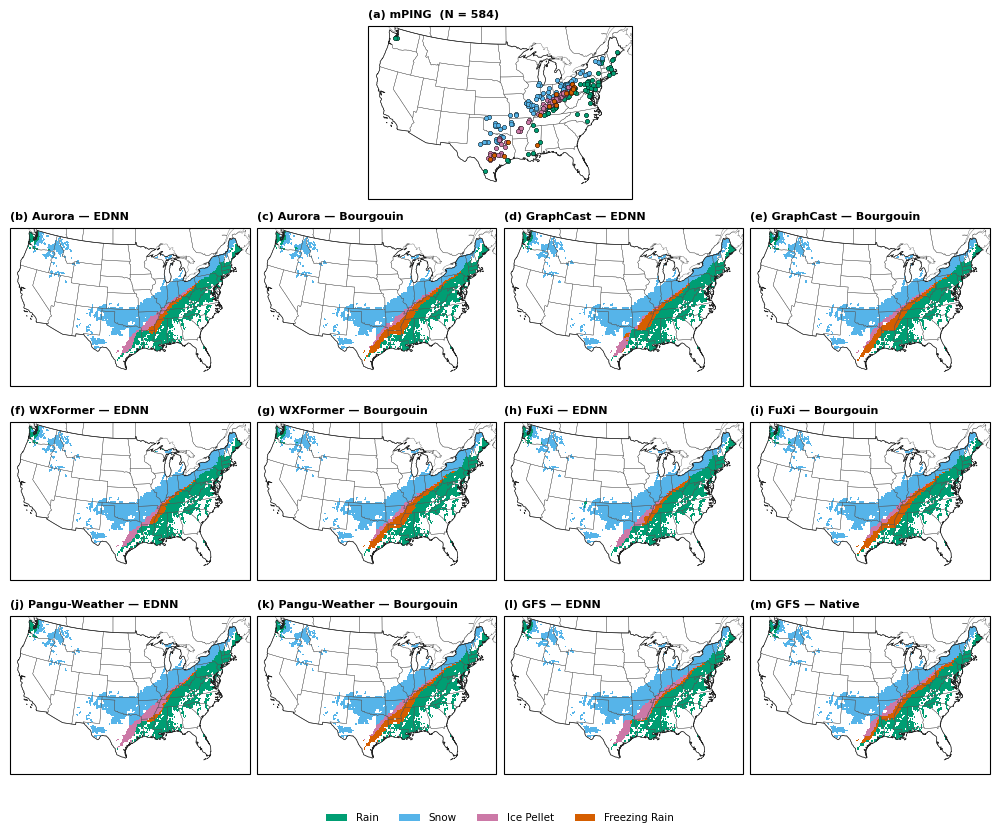

In [8]:
def setup_map(ax):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    if DRAW_STATES:
        try:
            ax.add_feature(cfeature.STATES.with_scale("50m"), linewidth=0.25, edgecolor="#555555")
        except Exception as e:
            warnings.warn(f"state lines not drawn: {e}")
    ax.add_geometries([CONUS], crs=ccrs.PlateCarree(), facecolor="none",
                      edgecolor="#222222", linewidth=0.5)

def draw_rap(ax):
    if RAP_T2M is None:
        return
    lat, lon, t = RAP_T2M
    ax.contour(lon, lat, t, levels=[0.0], colors="k", linewidths=0.6,
               transform=ccrs.PlateCarree())
    ax.contour(lon, lat, t, levels=[4.0], colors="k", linewidths=0.5, linestyles="--",
               transform=ccrs.PlateCarree())

def draw_ptype(ax, field):
    ax.pcolormesh(LON_T, LAT_T, field, cmap=CMAP, norm=NORM, shading="nearest",
                  transform=ccrs.PlateCarree(), rasterized=True)

def draw_mping(ax, size=9):
    for cls in CLASS_ORDER:                       # mixed-phase drawn last, on top
        o = obs[obs.obs_class == cls]
        ax.scatter(o.lon, o.lat, s=size, c=CLASS_COLORS[cls], edgecolors="k",
                   linewidths=0.25, transform=ccrs.PlateCarree(), zorder=5)

fig = plt.figure(figsize=(10.0, 8.4))
gs = GridSpec(4, 4, figure=fig, hspace=0.12, wspace=0.03,
              left=0.01, right=0.99, top=0.97, bottom=0.07)

ax = fig.add_subplot(gs[0, 1:3], projection=PROJ)
setup_map(ax)
draw_mping(ax)
ax.set_title(f"(a) mPING  (N = {len(obs):,})", loc="left", fontweight="bold")

for k, system in enumerate(SYSTEM_ORDER):
    r, c = 1 + k // 4, k % 4
    ax = fig.add_subplot(gs[r, c], projection=PROJ)
    setup_map(ax)
    draw_ptype(ax, maps[system])
    draw_rap(ax)
    ax.set_title(f"({LETTERS[k + 1]}) {system}", loc="left", fontweight="bold")

handles = [Patch(facecolor=CLASS_COLORS[c], edgecolor="none", label=c) for c in CLASS_ORDER]
if RAP_T2M is not None:
    handles += [Line2D([], [], color="k", lw=0.8, label="RAP 2-m T = 0 °C"),
                Line2D([], [], color="k", lw=0.8, ls="--", label="RAP 2-m T = 4 °C")]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False,
           fontsize=7.5, bbox_to_anchor=(0.5, 0.01))
fig.savefig(FIG / f"case_study_ptype_maps_{TAG}.pdf", dpi=300, bbox_inches="tight")
fig.savefig(FIG / f"case_study_ptype_maps_{TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Figure 2 — agreement maps

Computed on the displayed points only (CONUS, GFS ptype present).
- **(a)** Agreement among the 6 EDNN systems: fraction of systems that forecast the most common class.
- **(b)** The same for all 12 systems.
- **(c)** Number of AI models (0–5) for which EDNN and Bourgouin give different classes. This maps the algorithm difference discussed in Section 4.2.

Observed ice pellet and freezing rain reports are overlaid to show whether disagreement follows the mixed-phase corridor.

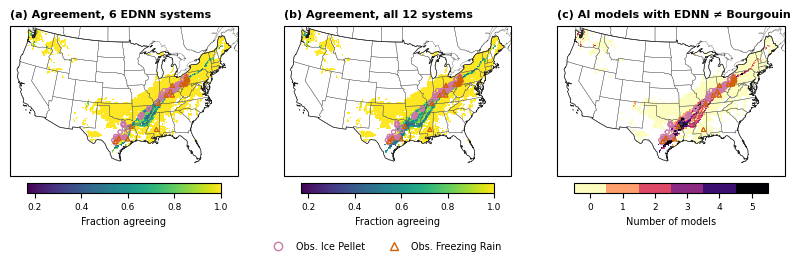

Displayed points where all 6 EDNN systems agree: 85.6%
Displayed points where all 12 systems agree:     79.4%
Displayed points with EDNN ≠ Bourgouin for ≥1 AI model: 18.2%


In [9]:
def agreement(systems):
    stack = np.stack([maps[s] for s in systems])                  # (n, lat, lon)
    counts = np.stack([(stack == k).sum(0) for k in range(4)])
    n_valid = np.isfinite(stack).sum(0)
    with np.errstate(invalid="ignore", divide="ignore"):
        frac = counts.max(0) / n_valid
    return np.where(SHOW & (n_valid > 0), frac, np.nan)

ednn = [s for s in SYSTEM_ORDER if s.endswith("EDNN")]
agree_ednn = agreement(ednn)
agree_all = agreement(SYSTEM_ORDER)
def differs(a, b):
    return (np.isfinite(a) & np.isfinite(b) & (a != b)).astype(float)
n_diff = sum(differs(maps[f"{m} — EDNN"], maps[f"{m} — Bourgouin"]) for m in AI_MODELS)
n_diff = np.where(SHOW, n_diff, np.nan)

fig, axes = plt.subplots(1, 3, figsize=(10.0, 2.9), subplot_kw={"projection": PROJ})
panels = [(agree_ednn, "(a) Agreement, 6 EDNN systems", "viridis", (1 / 6, 1.0), "Fraction agreeing"),
          (agree_all, "(b) Agreement, all 12 systems", "viridis", (1 / 6, 1.0), "Fraction agreeing"),
          (n_diff, "(c) AI models with EDNN ≠ Bourgouin", "magma_r", (-0.5, 5.5), "Number of models")]
for ax, (fld, title, cmap, (vmin, vmax), label) in zip(axes, panels):
    setup_map(ax)
    if title.startswith("(c)"):
        cm = plt.get_cmap(cmap, 6)
        im = ax.pcolormesh(LON_T, LAT_T, fld, cmap=cm, vmin=vmin, vmax=vmax, shading="nearest",
                           transform=ccrs.PlateCarree(), rasterized=True)
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.03, shrink=0.85, ticks=range(6))
    else:
        im = ax.pcolormesh(LON_T, LAT_T, fld, cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest",
                           transform=ccrs.PlateCarree(), rasterized=True)
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", pad=0.03, shrink=0.85)
    cb.set_label(label, fontsize=7)
    cb.ax.tick_params(labelsize=6.5)
    for cls, mk in (("Ice Pellet", "o"), ("Freezing Rain", "^")):
        o = obs[obs.obs_class == cls]
        ax.scatter(o.lon, o.lat, s=9, marker=mk, facecolors="none", edgecolors=CLASS_COLORS[cls],
                   linewidths=0.7, transform=ccrs.PlateCarree(), zorder=5)
    draw_rap(ax)
    ax.set_title(title, loc="left", fontweight="bold")

h = [Line2D([], [], ls="", marker="o", mfc="none", mec=CLASS_COLORS["Ice Pellet"], label="Obs. Ice Pellet"),
     Line2D([], [], ls="", marker="^", mfc="none", mec=CLASS_COLORS["Freezing Rain"], label="Obs. Freezing Rain")]
fig.legend(handles=h, loc="lower center", ncol=2, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.04))
fig.savefig(FIG / f"case_study_agreement_{TAG}.pdf", dpi=300, bbox_inches="tight")
plt.show()

on = lambda a: a[np.isfinite(a)]
print(f"Displayed points where all 6 EDNN systems agree: {np.mean(on(agree_ednn) == 1):.1%}")
print(f"Displayed points where all 12 systems agree:     {np.mean(on(agree_all) == 1):.1%}")
print(f"Displayed points with EDNN ≠ Bourgouin for ≥1 AI model: {np.mean(on(n_diff) >= 1):.1%}")

In [10]:
per_model = {m: np.mean(on(np.where(SHOW, differs(maps[f"{m} — EDNN"], maps[f"{m} — Bourgouin"]), np.nan)))
             for m in AI_MODELS}
for m, v in per_model.items():
    print(f"{m:14s} EDNN ≠ Bourgouin at {v:.1%} of displayed points")
print(f"Mean over AI models: {np.mean(list(per_model.values())):.1%}")

Aurora         EDNN ≠ Bourgouin at 9.0% of displayed points
GraphCast      EDNN ≠ Bourgouin at 8.1% of displayed points
WXFormer       EDNN ≠ Bourgouin at 9.3% of displayed points
FuXi           EDNN ≠ Bourgouin at 8.5% of displayed points
Pangu-Weather  EDNN ≠ Bourgouin at 9.8% of displayed points
Mean over AI models: 8.9%


In [11]:
from itertools import combinations
rate = lambda a, b: np.mean(on(np.where(SHOW, differs(maps[a], maps[b]), np.nan)))
ai_ednn = [f"{m} — EDNN" for m in AI_MODELS]
pairs_ai = [rate(a, b) for a, b in combinations(ai_ednn, 2)]
pairs_all = [rate(a, b) for a, b in combinations(ednn, 2)]
print(f"AI-model EDNN pairs (10): mean {np.mean(pairs_ai):.1%}, range {min(pairs_ai):.1%}–{max(pairs_ai):.1%}")
print(f"All EDNN pairs incl. GFS (15): mean {np.mean(pairs_all):.1%}, range {min(pairs_all):.1%}–{max(pairs_all):.1%}")

AI-model EDNN pairs (10): mean 6.6%, range 3.1%–9.0%
All EDNN pairs incl. GFS (15): mean 7.0%, range 3.1%–9.5%


In [12]:
# nd = on(n_diff)
# for k in range(6):
#     print(f"EDNN ≠ Bourgouin for exactly {k} AI model(s): {np.mean(nd == k):.1%}")
# print(f"\nAll 5 AI models change:            {np.mean(nd == 5):.1%}")
# print(f"Majority (≥3 of 5) change:         {np.mean(nd >= 3):.1%}")
# # share of the 18.2% where all five agree that the algorithm matters
# print(f"Of points with ≥1 change, all 5:   {np.mean(nd[nd >= 1] == 5):.1%}")

## 10. Point verification at the case time

Each mPING report is matched to the nearest **native** grid point of every system, with **no display masks**, as in notebook 01 Only reports with a valid forecast from **all 12 systems** are scored (the common-valid rule of notebook 01), and reports farther than `MAX_POINT_KM` from a grid point are invalid. Native GFS −1 is a valid forecast and counts as a miss.

- `case_study_point_verification_*.csv`: accuracy and the fraction correct for each observed class.
- `case_study_ip_fzra_fate_*.csv`: for observed ice pellets and freezing rain, the fraction forecast as each class (the case-study counterpart of notebook 02).

The numbers come from a single time and a few hundred reports, so use them to describe the case, not to rank systems.

In [13]:
CODE_TO_NAME = {**CLASS_NAMES, -1: NONE_LABEL}
pts = _xyz(obs.lat.to_numpy(), obs.lon.to_numpy())
preds = {}
for system in SYSTEM_ORDER:
    lat2, lon2, v = native[system]
    d, i = _tree(lat2, lon2).query(pts)
    pred = v.ravel()[i].copy()
    far = _chord_to_km(d) > MAX_POINT_KM
    if far.any():
        print(f"[warn] {system}: {far.sum()} reports > {MAX_POINT_KM:.0f} km from a grid point")
    pred[far] = np.nan
    preds[system] = pred

# common-valid reports: every system has a valid forecast (as in notebook 01)
P = pd.DataFrame(preds)
common_ok = P.notna().all(axis=1).to_numpy()
print(f"Reports valid for all 12 systems: {common_ok.sum()} of {len(obs)}")
o_all = obs[common_ok].reset_index(drop=True)
P = P[common_ok].reset_index(drop=True).astype(int)

rows, fate_rows = [], []
for system in SYSTEM_ORDER:
    pred, oc = P[system], o_all.obs_code
    rec = {"System": system, "N": len(pred), "accuracy": float((pred == oc).mean())}
    for k, cls in CLASS_NAMES.items():
        m = oc == k
        rec[f"n_{cls}"] = int(m.sum())
        rec[f"correct_{cls}"] = float((pred[m] == k).mean()) if m.any() else np.nan
    rows.append(rec)
    for cls in ("Ice Pellet", "Freezing Rain"):
        m = o_all.obs_class == cls
        dest = pred[m].map(CODE_TO_NAME).value_counts(normalize=True)
        fate_rows.append({"obs_class": cls, "System": system, "n": int(m.sum()),
                          **{f"as_{c}": float(dest.get(c, 0.0)) for c in CLASS_ORDER + [NONE_LABEL]}})

pv = pd.DataFrame(rows).set_index("System")
fate = (pd.DataFrame(fate_rows)
        .assign(System=lambda d: pd.Categorical(d.System, SYSTEM_ORDER, ordered=True))
        .sort_values(["obs_class", "System"], ascending=[False, True])
        .set_index(["obs_class", "System"]))
pv.to_csv(OUT / f"case_study_point_verification_{TAG}.csv")
fate.to_csv(OUT / f"case_study_ip_fzra_fate_{TAG}.csv")

print("Point verification:")
display(pv.round(3))
print("Observed ice pellets / freezing rain — fraction forecast as each class:")
display(fate.round(2))

Reports valid for all 12 systems: 584 of 584
Point verification:


,N,accuracy,n_Rain,correct_Rain,n_Snow,correct_Snow,n_Ice Pellet,correct_Ice Pellet,n_Freezing Rain,correct_Freezing Rain
System,,,,,,,,,,
Aurora — EDNN,584,0.767,146,0.822,216,0.991,186,0.559,36,0.278
Aurora — Bourgouin,584,0.757,146,0.781,216,0.991,186,0.495,36,0.611
GraphCast — EDNN,584,0.699,146,0.877,216,1.000,186,0.312,36,0.167
GraphCast — Bourgouin,584,0.736,146,0.822,216,0.991,186,0.419,36,0.500
WXFormer — EDNN,584,0.661,146,0.877,216,1.000,186,0.204,36,0.111
WXFormer — Bourgouin,584,0.699,146,0.767,216,1.000,186,0.312,36,0.611
FuXi — EDNN,584,0.705,146,0.877,216,1.000,186,0.301,36,0.333
FuXi — Bourgouin,584,0.726,146,0.767,216,1.000,186,0.419,36,0.500
Pangu-Weather — EDNN,584,0.757,146,0.863,216,0.991,186,0.538,36,0.056


Observed ice pellets / freezing rain — fraction forecast as each class:


n  as_Rain  as_Snow  as_Ice Pellet  \
obs_class     System                                                            
Ice Pellet    Aurora — EDNN              186     0.00     0.41           0.56   
              Aurora — Bourgouin         186     0.00     0.24           0.49   
              GraphCast — EDNN           186     0.01     0.35           0.31   
              GraphCast — Bourgouin      186     0.00     0.18           0.42   
              WXFormer — EDNN            186     0.00     0.67           0.20   
              WXFormer — Bourgouin       186     0.00     0.33           0.31   
              FuXi — EDNN                186     0.00     0.48           0.30   
              FuXi — Bourgouin           186     0.00     0.22           0.42   
              Pangu-Weather — EDNN       186     0.01     0.38           0.54   
              Pangu-Weather — Bourgouin  186     0.01     0.25           0.44   
              GFS — EDNN                 186     0.00     0.30           0.70   
              GFS — Native               186     0.00     0.18           0.55   
Freezing Rain Aurora — EDNN               36     0.28     0.11           0.33   
              Aurora — Bourgouin          36     0.17     0.11           0.11   
              GraphCast — EDNN            36     0.56     0.11           0.17   
              GraphCast — Bourgouin       36     0.28     0.11           0.11   
              WXFormer — EDNN             36     0.33     0.33           0.22   
              WXFormer — Bourgouin        36     0.11     0.17           0.11   
              FuXi — EDNN                 36     0.33     0.11           0.22   
              FuXi — Bourgouin            36     0.28     0.11           0.11   
              Pangu-Weather — EDNN        36     0.44     0.11           0.39   
              Pangu-Weather — Bourgouin   36     0.33     0.11           0.17   
              GFS — EDNN                  36     0.06     0.11           0.44   
              GFS — Native                36     0.06     0.11           0.11   

                                         as_Freezing Rain  as_No ptype  
obs_class     System                                                    
Ice Pellet    Aurora — EDNN                          0.03         0.00  
              Aurora — Bourgouin                     0.27         0.00  
              GraphCast — EDNN                       0.32         0.00  
              GraphCast — Bourgouin                  0.40         0.00  
              WXFormer — EDNN                        0.13         0.00  
              WXFormer — Bourgouin                   0.35         0.00  
              FuXi — EDNN                            0.22         0.00  
              FuXi — Bourgouin                       0.37         0.00  
              Pangu-Weather — EDNN                   0.08         0.00  
              Pangu-Weather — Bourgouin              0.30         0.00  
              GFS — EDNN                             0.00         0.00  
              GFS — Native                           0.13         0.14  
Freezing Rain Aurora — EDNN                          0.28         0.00  
              Aurora — Bourgouin                     0.61         0.00  
              GraphCast — EDNN                       0.17         0.00  
              GraphCast — Bourgouin                  0.50         0.00  
              WXFormer — EDNN                        0.11         0.00  
              WXFormer — Bourgouin                   0.61         0.00  
              FuXi — EDNN                            0.33         0.00  
              FuXi — Bourgouin                       0.50         0.00  
              Pangu-Weather — EDNN                   0.06         0.00  
              Pangu-Weather — Bourgouin              0.39         0.00  
              GFS — EDNN                             0.39         0.00  
              GFS — Native                           0.61         0.11